## Problem Statement

**Business context**
Olist's review scores are falling, and bad reviews (1-2 stars) hurt seller
retention, repeat purchases, and commission revenue. Our analysis showed that
late delivery is the strongest single driver: late orders get bad reviews 6.7x
as often as on-time orders. But the support team only finds out about an
unhappy customer after the review is posted, when it is too late to act.

**The problem**
Olist has no way to tell, before an order arrives, which orders are likely to
end up with a poor review. Without this, the support and seller-management
teams cannot prioritize their limited time.

**Objective**
Build a linear regression model that predicts the review score (1 to 5 stars)
of an order using only information available before delivery. Orders with the
lowest predicted scores are flagged as "high risk" so the team can step in
early, for example by contacting the customer or escalating with the seller.

**Target variable:** `review_score` (1-5 stars)

**Input features (known before delivery):**
- At purchase: promised delivery days, freight ratio, price, distance,
  same-state flag, number of items, product weight, repeat-customer flag,
  seller's past late rate and past low-review rate
- At shipping: seller handoff time (days from approval to carrier pickup)

**Not allowed (data leakage):** `is_late`, `days_late`, `delivery_days`,
review text, or any review data. These are only known after delivery.

**Success criteria**
1. The model beats the baseline of predicting the average score for every
   order (lower MAE and RMSE on unseen data).
2. Flagging the riskiest 10% of orders catches clearly more bad reviews than
   picking 10% of orders at random.
3. The model is explainable: each coefficient shows how much a factor moves
   the predicted score, in plain language a manager can understand.

**Validation approach**
Train on orders before May 2018, test on May-Aug 2018, so the model is
judged on the future, not on data it has already seen.

**Limitations**
Reviews also depend on factors we cannot see (product quality, customer
expectations), so the model is a prioritization tool, not a perfect predictor.
Linear regression also treats star ratings as evenly spaced numbers and
assumes straight-line effects, which is a simplification.

In [2]:
import pandas as pd, numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Gafoo\OneDrive\Documents\GitHub\Olist-Customer-Experience-Analytics\notebooks\data\clean_orders.csv",
                 parse_dates=["order_purchase_timestamp"])
df.shape


(95560, 55)

In [3]:
features = ["estimated_days", "freight_ratio", "items_price", "distance_km",
            "same_state", "n_items", "product_weight_g", "is_repeat_customer",
            "seller_prior_late_rate", "seller_prior_low_rate"]
features_v2 = features + ["seller_handoff_days"]   # known once the seller ships

In [4]:
train = df[df.order_purchase_timestamp < "2018-05-01"]
test  = df[df.order_purchase_timestamp >= "2018-05-01"]

In [5]:
medians = train[features_v2].median()          # TRAIN values only
X_train = train[features_v2].fillna(medians)
X_test  = test[features_v2].fillna(medians)
y_train, y_test = train.review_score, test.review_score
print(len(train), len(test))

70318 25242


“I trained on older orders and tested on the newest ones, like predicting the future from the past. Missing values were filled using training data only.”

## Step 1: Train/test split

| Set | Orders | Period |
|---|---|---|
| Training | 70,318 | Jan 2017 to Apr 2018 |
| Testing | 25,242 | May 2018 to Aug 2018 |

**What I did:** I trained the model on older orders and tested it on the newest ones, instead of mixing them randomly.

**Why:** In real life we predict the future from the past. A random split would let the model "see" the future, which makes results look better than they would be in practice.

**Features used:** only information known before delivery (price, freight, distance, promised delivery days, seller history, items in the order, seller handoff time). I excluded `is_late`, `days_late`, `delivery_days` and review data because they are only known after delivery (data leakage).

**Step 2: The dumb baseline**

In [6]:
baseline = np.full(len(y_test), y_train.mean())
print("Baseline (always predict the average score)")
print("  MAE :", round(mean_absolute_error(y_test, baseline), 3))
print("  RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline)), 3))

Baseline (always predict the average score)
  MAE : 0.955
  RMSE: 1.197


## Step 2: Baseline (the score to beat)

| Baseline: predict the average score for every order | Value |
|---|---|
| MAE | 0.955 stars |
| RMSE | 1.197 |

**What it means:** If we guessed the same average score for every order, we would be off by about 0.95 stars on average. Any useful model must do better than this.

**Terms:**
- **MAE:** the average number of stars the prediction is off by.
- **RMSE:** like MAE, but big misses count more (an order predicted 4 that got 1 star hurts a lot).

**Step 3: Linear regression, two versions**

In [7]:
def fit_eval(name, cols):
    sc = StandardScaler().fit(X_train[cols])
    model = LinearRegression().fit(sc.transform(X_train[cols]), y_train)
    pred = model.predict(sc.transform(X_test[cols]))
    print(f"{name}: MAE {mean_absolute_error(y_test, pred):.3f} | "
          f"RMSE {np.sqrt(mean_squared_error(y_test, pred)):.3f} | "
          f"R² {r2_score(y_test, pred):.3f}")
    return model, pred

lin1, pred1 = fit_eval("Version 1 (purchase info)", features)
lin2, pred2 = fit_eval("Version 2 (+ shipping info)", features_v2)

Version 1 (purchase info): MAE 0.953 | RMSE 1.186 | R² -0.006
Version 2 (+ shipping info): MAE 0.939 | RMSE 1.174 | R² 0.015


## Step 3: Model results

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Baseline (average) | 0.955 | 1.197 | n/a |
| Version 1: purchase info only | 0.953 | 1.186 | -0.006 |
| Version 2: purchase + shipping info | **0.939** | **1.174** | **0.015** |

**What it means in plain English:**
- **Version 1** is barely better than guessing the average (0.2% lower MAE). Its R² is slightly negative, meaning it explains none of the variation in star ratings on its own.
- **Version 2** is better: MAE falls by about 1.7% and RMSE by about 1.9%. Adding seller handoff time (known once the seller ships) is what helps.
- **R² of 0.015** means the model explains only about 1.5% of why ratings differ between orders.

**Why is R² so low?** Star ratings depend mostly on things we can't see before delivery: whether the package actually arrives on time, product quality, and the customer's mood and expectations. Before delivery, we only have weak clues.

**So is the model useless?** No. Predicting the *exact* score is hard, but **ranking orders from riskiest to safest** can still work. That is what the next step tests.

**Step 4: The business table (most important)**

Rank orders from lowest predicted score to highest, and check how many real bad reviews sit in the lowest group.

In [8]:
def top_k(pred, y_score, ks=(0.05, 0.10, 0.20)):
    bad = (y_score <= 2).astype(int).values
    order = np.argsort(pred)            # lowest predicted score first
    rows = []
    for k in ks:
        n = int(len(pred) * k)
        flagged = bad[order[:n]]
        rows.append({"flag riskiest": f"{k:.0%}",
                     "bad reviews caught": f"{flagged.sum() / bad.sum():.0%}",
                     "times better than random": round(flagged.mean() / bad.mean(), 1)})
    return pd.DataFrame(rows)

print(top_k(pred1, y_test))
print(top_k(pred2, y_test))

  flag riskiest bad reviews caught  times better than random
0            5%                12%                       2.5
1           10%                24%                       2.4
2           20%                36%                       1.8
  flag riskiest bad reviews caught  times better than random
0            5%                15%                       3.0
1           10%                24%                       2.4
2           20%                39%                       1.9


## Step 4: Does the model find the risky orders? (the business test)

I ranked all test orders from lowest to highest predicted score, flagged the riskiest ones, and counted how many real bad reviews (1-2 stars) were inside the flagged group.

| Flag the riskiest | Version 1: bad reviews caught | Version 1: vs random | Version 2: bad reviews caught | Version 2: vs random |
|---|---|---|---|---|
| 5% | 12% | 2.5x | **15%** | **3.0x** |
| 10% | 24% | 2.4x | 24% | 2.4x |
| 20% | 36% | 1.8x | **39%** | **1.9x** |

**How to read it:** If the support team contacts only the riskiest 10% of orders, they reach about **24% of all future bad reviews**. Picking 10% at random would catch only 10%. So the model is **2.4x better than random**.

**Precision in plain words:** about 1 in 4 flagged orders ends up with a bad review, compared with about 1 in 10 for a random order.

**Honest reading:** The model is a modest but real help. It will not catch most bad reviews, because most are caused by things that happen after the order ships. Version 2 helps most when flagging the very top 5% (3.0x), where seller handoff time is a strong signal.

**Why accuracy is not used:** about 90% of orders get good reviews, so "always predict good" would be 90% accurate and catch zero bad reviews.

**Step 5: What drives the predictions?**

seller_handoff_days      -0.197
n_items                  -0.153
distance_km              -0.076
seller_prior_low_rate    -0.069
seller_prior_late_rate   -0.017
product_weight_g         -0.012
freight_ratio            -0.011
items_price              -0.001
is_repeat_customer        0.012
estimated_days            0.065
same_state                0.086
dtype: float64


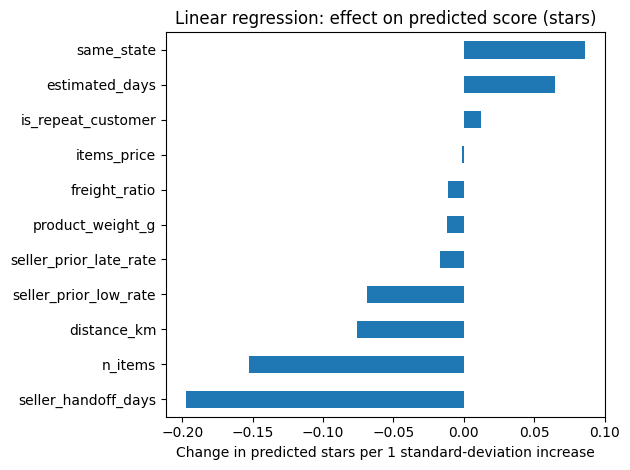

In [9]:
coef = pd.Series(lin2.coef_, index=features_v2).sort_values()
coef.plot(kind="barh", title="Linear regression: effect on predicted score (stars)")
plt.xlabel("Change in predicted stars per 1 standard-deviation increase")
plt.tight_layout()
plt.savefig("images/10_coefficients.png", dpi=150)
print(coef.round(3))

## Step 5: What drives the predicted score?

*(Chart: images/10_coefficients.png)*

Each bar shows how many stars the predicted score changes when a factor goes up by one standard deviation, with the other factors held equal.

| Factor | Effect | Plain-English meaning |
|---|---|---|
| **seller_handoff_days** | **-0.197** | Strongest driver. Sellers who take longer to hand the package to the carrier get lower predicted scores (about 0.2 stars per standard deviation) |
| **n_items** | **-0.153** | Orders with more items score lower. Larger orders have more things that can go wrong (partial delivery, wrong item) |
| distance_km | -0.076 | Longer distances lower the score a little |
| seller_prior_low_rate | -0.069 | Sellers with a history of bad reviews tend to get more |
| seller_prior_late_rate | -0.017 | Small effect (its information overlaps with handoff time and low-review history) |
| product_weight_g | -0.012 | Very small |
| freight_ratio | -0.011 | Very small |
| items_price | -0.001 | No effect |
| is_repeat_customer | +0.012 | Very small |
| **estimated_days** | **+0.065** | Longer promised delivery windows give higher scores (customers are less often disappointed when the promise is generous) |
| **same_state** | **+0.086** | Orders from a seller in the customer's own state score higher, on top of the distance effect |

**Business takeaways:**
1. **The seller's speed at handing over the package is the biggest lever we can see**, which points to seller handoff targets (for example, a maximum number of days to ship) rather than only blaming the logistics partner.
2. **Promising a slightly longer delivery window may protect ratings**, though it could reduce sales conversion, so it should be tested before rollout.
3. **Large multi-item orders deserve extra attention**, because they are riskier.

**Caution:** These are associations in observational data, not proven causes. Factors that overlap (for example, handoff time and seller history) share the credit, so don't over-read small differences between bars.

**Step 6: Quick check that the model makes sense**

In [10]:
test_check = test.assign(pred=pred2)
test_check["risk_group"] = pd.qcut(test_check.pred, 5,
                                   labels=["Riskiest 20%", "2", "3", "4", "Safest 20%"])
print(test_check.groupby("risk_group", observed=True)
                .agg(predicted=("pred", "mean"),
                     actual_score=("review_score", "mean"),
                     bad_review_rate=("low_review", "mean")).round(3))

              predicted  actual_score  bad_review_rate
risk_group                                            
Riskiest 20%      3.709         3.908            0.193
2                 4.047         4.256            0.104
3                 4.162         4.379            0.076
4                 4.262         4.433            0.067
Safest 20%        4.391         4.483            0.061


## Step 6: Sanity check by risk group

I split the test orders into five groups from riskiest to safest (based on predicted score) and compared them with what actually happened.

| Risk group | Predicted score | Actual score | Actual bad-review rate |
|---|---|---|---|
| Riskiest 20% | 3.71 | 3.91 | **19.3%** |
| Group 2 | 4.05 | 4.26 | 10.4% |
| Group 3 | 4.16 | 4.38 | 7.6% |
| Group 4 | 4.26 | 4.43 | 6.7% |
| Safest 20% | 4.39 | 4.48 | **6.1%** |

**What it means:** The model sorts orders in the right order. The actual score rises and the bad-review rate falls at every step. The riskiest group has a bad-review rate of **19.3% vs 6.1%** for the safest group, about **3x higher**.

**Why predicted scores are lower than actual scores:** The model consistently predicts a bit lower than reality. This is probably because the test months had slightly higher ratings than the training months. It means the model is better at **ranking** orders than at predicting the exact star score, which is why we use it for prioritizing, not for forecasting precise ratings.

**How a business would use it:** Send the riskiest 20% of orders to the support team for a proactive check (tracking status, a message to the customer, or a nudge to the seller), and leave the rest alone.

## Conclusion

1. **The model works as a ranking tool, not an exact predictor.** R² is low (0.015), but the riskiest 20% of orders have 3x the bad-review rate of the safest 20%.
2. **Flagging the riskiest 10% catches 24% of bad reviews, 2.4x better than random.** Flagging 5% with shipping information catches 15% (3.0x).
3. **Shipping information helps.** Adding seller handoff time improved MAE from 0.953 to 0.939 and made the top 5% much sharper.
4. **Main drivers:** slow seller handoff, larger orders, longer distance, and sellers with a bad history.
5. **Why it's not stronger:** The biggest driver of bad reviews, late delivery (shown in the statistics phase), is only known after the package arrives. Before delivery, we only see weak clues.

**Limits**
- Linear regression treats star ratings as evenly spaced numbers and assumes straight-line effects.
- Reviews depend on things we can't see (product quality, customer mood).
- Coefficients show associations, not proven causes.

**Next steps (if there were more time)**
- Try logistic regression on the "bad review yes/no" target, which fits the problem better.
- Add an in-transit version: once an order passes its promised date without being delivered, the risk is known to be high.